In [ ]:
!git clone https://github.com/Tzomy/ML_titanic

Cloning into 'ML_titanic'...
remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 4 (delta 0), reused 0 (delta 0), pack-reused 0
Receiving objects: 100% (4/4), 32.85 KiB | 4.69 MiB/s, done.


In [ ]:
import pandas as pd
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler

<h3>Sistemare i dati in input</h3>

In [ ]:
cols = ['PassengerId','Survived','Pclass','Name','Sex','Age','SibSp','Parch','Ticket','Fare','Cabin','Embarked']
test_df = pd.read_csv("ML_titanic/test.csv")
train_df = pd.read_csv("ML_titanic/train.csv")
train_df["Sex"] = (train_df["Sex"] == "male").astype(int) #male 1, women 0
test_df["Sex"] = (test_df["Sex"] == "male").astype(int)

In [ ]:
train_df["Cabin"] = (train_df["Cabin"]).astype(str)
test_df["Cabin"] = (test_df["Cabin"]).astype(str)
train_df["Embarked"] = (train_df["Embarked"]).astype(str)
test_df["Embarked"] = (test_df["Embarked"]).astype(str)

<p>Trasformiamo qualsiasi informazione che non sia numerica in stringa in modo che non ci dia problemi</p>

In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    int64  
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        891 non-null    object 
 11  Embarked     891 non-null    object 
dtypes: float64(2), int64(6), object(4)
memory usage: 83.7+ KB


In [ ]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    object 
 3   Sex          418 non-null    int64  
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    object 
 8   Fare         417 non-null    float64
 9   Cabin        418 non-null    object 
 10  Embarked     418 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 36.0+ KB


<p>E notiamo che le uniche informazioni mancanti che troviamo sono per l'età, che andremo poi <br>
a sistemare, perchè essa è una variabile categorica, per cui dobbiamo rifattorizzarla </p>

In [ ]:
train_df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,nan,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,nan,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,nan,S


In [ ]:
test_df.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",1,34.5,0,0,330911,7.8292,nan,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",0,47.0,1,0,363272,7.0000,nan,S
2,894,2,"Myles, Mr. Thomas Francis",1,62.0,0,0,240276,9.6875,nan,Q
3,895,3,"Wirz, Mr. Albert",1,27.0,0,0,315154,8.6625,nan,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",0,22.0,1,1,3101298,12.2875,nan,S


<p>Processiamo successivamente le età in modo da trasformare un carattere quantitativo discreto ad una variabile <br>
qualitativa ordinabile sulla quale possiamo creare delle variabili dummy per avere informazioni ulteriori</p>
<p>Creiamo quindi delle categorie 'Missing', 'Infant', 'Child', 'Teenager', 'Young Adult', 'Adult', 'Senior' in base <br>
a delle fasce di età scelte arbitrariamente</p>

In [ ]:
def process_age(datafr, cut, ages):
    datafr["Age"] = datafr["Age"].fillna(-1)
    datafr["Age_categories"] = pd.cut(datafr["Age"], cut, labels=ages)
    return datafr

ages = [-1, 0, 5, 12, 18, 35, 60, 100]
age_classes = ['Missing', 'Infant', 'Child', 'Teenager', 'Young Adult', 'Adult', 'Senior']


train = process_age(train_df, ages, age_classes)
test = process_age(test_df, ages, age_classes)

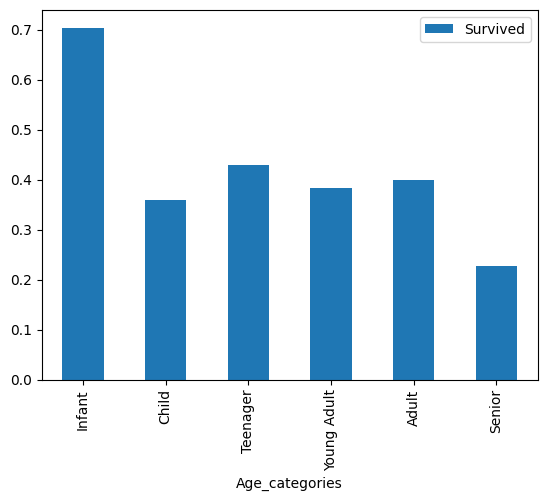

In [ ]:
age_plot = train.pivot_table(index="Age_categories",values="Survived")
age_plot.plot.bar()
plt.show()

<p>survived Yes = 1, No = 0 <br />
ticket class <br />
sibsp => number of siblings / spouses aboard <br />
parch => # of parents / children aboard the Titanic <br />
ticket => Ticket number <br />
fare => Passenger fare <br />
cabin => Cabin number <br />
embarked => Port of Embarkation <br />
</p>



In [ ]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_categories
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,nan,S,Young Adult
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C85,C,Adult
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,nan,S,Young Adult
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,C123,S,Young Adult
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,nan,S,Young Adult


<p>Creiamo ora qualche grafico per capire qualcosa di più sui dati che troviamo come input </p>

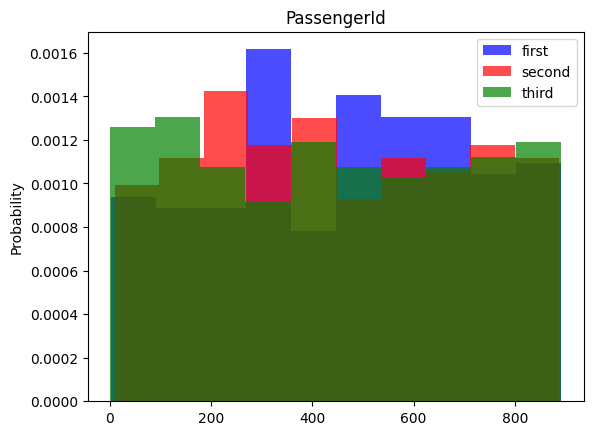

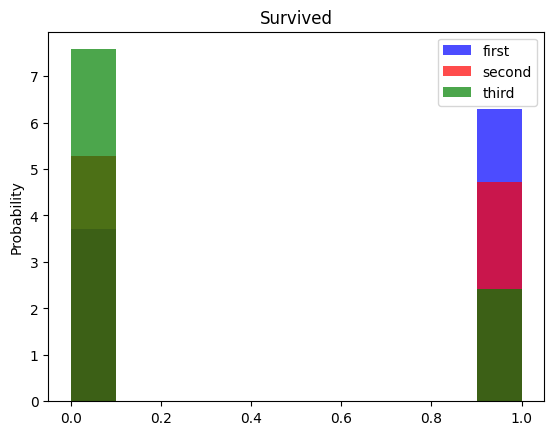

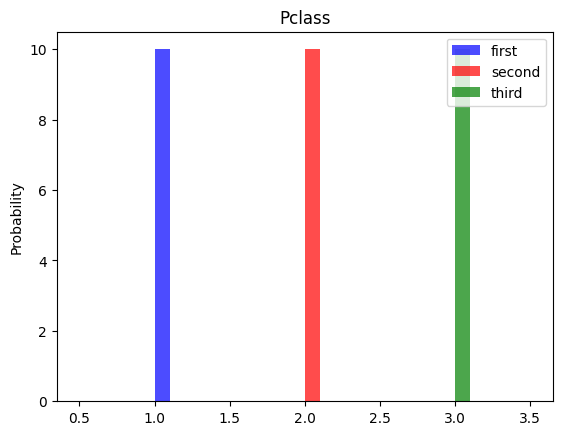

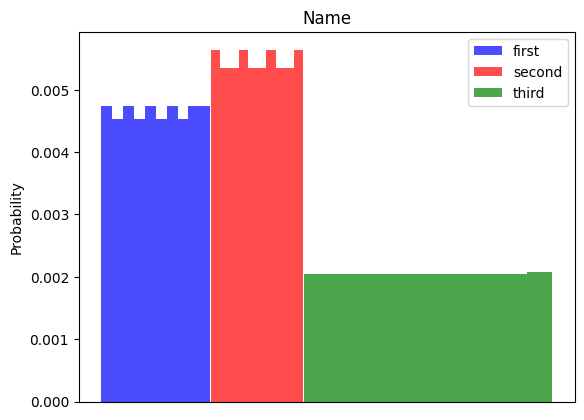

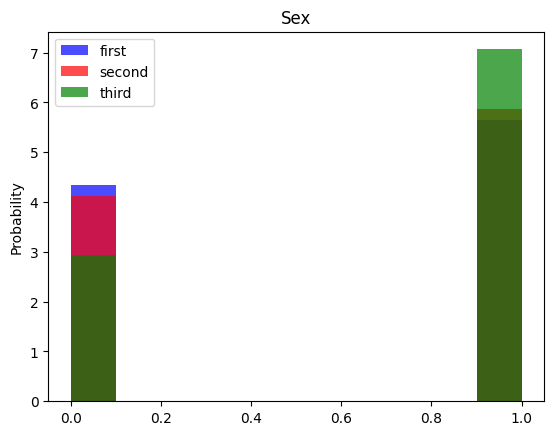

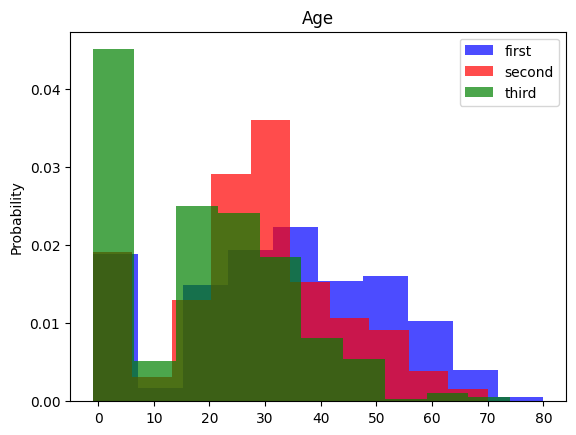

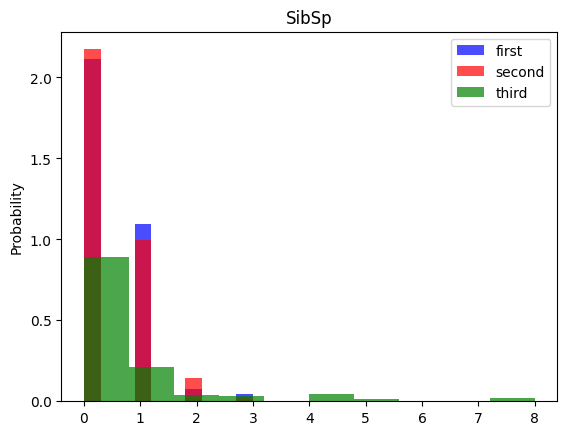

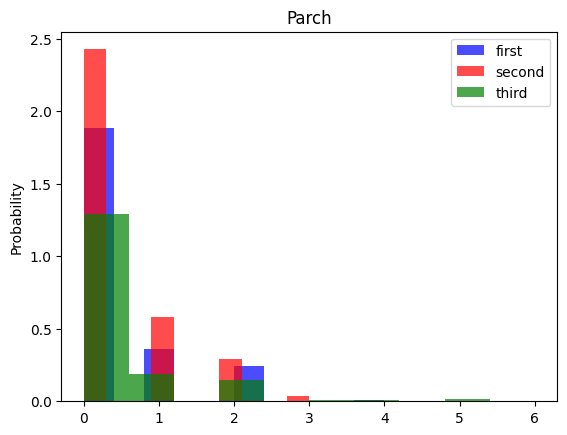

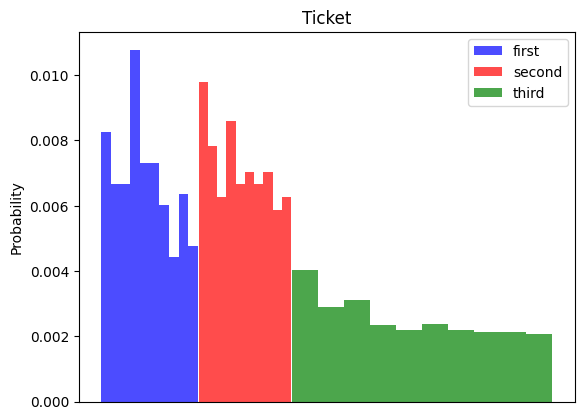

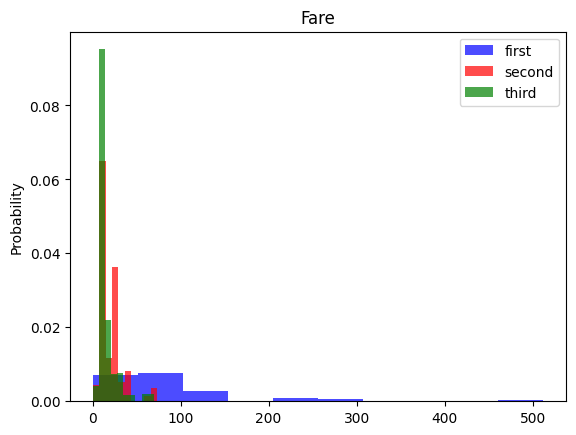

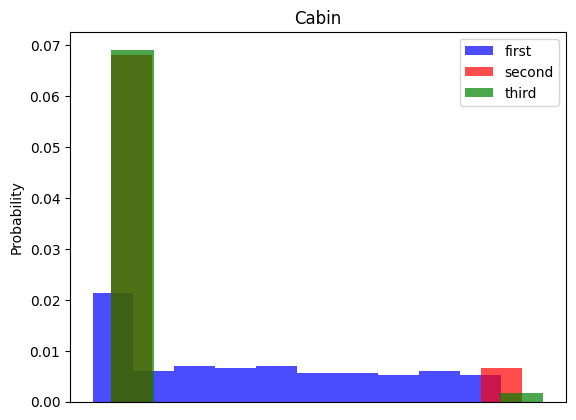

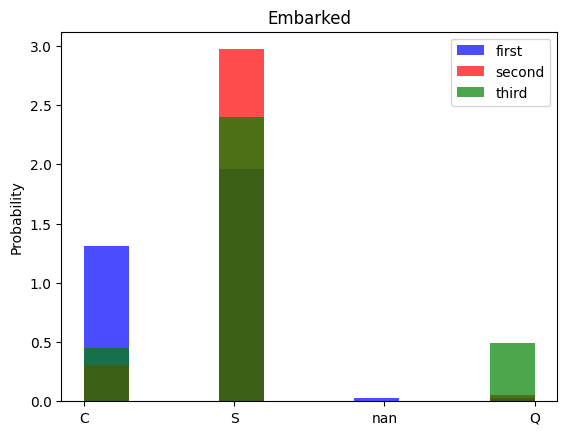

In [ ]:
for label in cols:
    plt.hist(train[train["Pclass"] == 1][label], color = 'blue', label = 'first', alpha = 0.7, density = True)
    plt.hist(train[train["Pclass"] == 2][label], color = 'red', label = 'second', alpha = 0.7, density = True)
    plt.hist(train[train["Pclass"] == 3][label], color = 'green', label = 'third', alpha = 0.7, density = True)

    plt.title(label)
    plt.ylabel("Probability")
    plt.legend()
    if label == "Name" or label == "Ticket" or label == "Cabin":
        plt.xticks([])
    plt.show()

In [ ]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_categories
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,nan,S,Young Adult
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C85,C,Adult
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,nan,S,Young Adult
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,C123,S,Young Adult
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,nan,S,Young Adult


In [ ]:
classes = pd.get_dummies(train["Pclass"],prefix="Pclass").astype(int)
classes.head()

,Pclass_1,Pclass_2,Pclass_3
0,0,0,1
1,1,0,0
2,0,0,1
3,1,0,0
4,0,0,1


In [ ]:
import seaborn as sns

<Axes: >

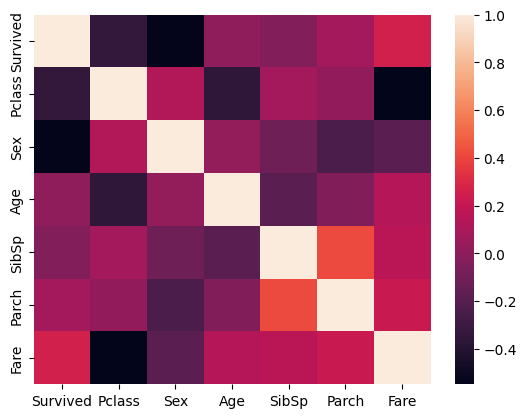

In [ ]:
sns.heatmap(train[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']].corr())

In [ ]:
def append_dummies(df, column):
    dummies = pd.get_dummies(df[column], prefix=column).astype(int)
    df = pd.concat([df, dummies], axis=1)
    return df

train = append_dummies(train, "Pclass")
test = append_dummies(test, "Pclass")
train = append_dummies(train,"Age_categories")
test = append_dummies(test,"Age_categories")

train.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,Pclass_1,Pclass_2,Pclass_3,Age_categories_Missing,Age_categories_Infant,Age_categories_Child,Age_categories_Teenager,Age_categories_Young Adult,Age_categories_Adult,Age_categories_Senior
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,...,0,0,1,0,0,0,0,1,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,...,1,0,0,0,0,0,0,0,1,0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,...,0,0,1,0,0,0,0,1,0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,...,1,0,0,0,0,0,0,1,0,0
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,...,0,0,1,0,0,0,0,1,0,0


In [ ]:
test.columns

Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked', 'Age_categories', 'Pclass_1',
       'Pclass_2', 'Pclass_3', 'Age_categories_Missing',
       'Age_categories_Infant', 'Age_categories_Child',
       'Age_categories_Teenager', 'Age_categories_Young Adult',
       'Age_categories_Adult', 'Age_categories_Senior'],
      dtype='object')

In [ ]:
from sklearn.model_selection import train_test_split

columns = ['Sex', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Age_categories_Missing','Age_categories_Infant', 'Age_categories_Child',
           'Age_categories_Teenager', 'Age_categories_Young Adult', 'Age_categories_Adult', 'Age_categories_Senior']
X_train, X_test, y_train, y_test = train_test_split(train[columns], train["Survived"], test_size=0.2,random_state=0)


In [ ]:
X_train.shape

(712, 11)

In [ ]:
y_train.shape

(712,)

In [ ]:
X_test.shape

(179, 11)

<h1>Modello Knn</h1>

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import log_loss

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=3,
                                 weights='uniform',
                                 algorithm='kd_tree',
                                 n_jobs=3)
knn_model.fit(X_train, y_train)

KNeighborsClassifier(algorithm='kd_tree', n_jobs=3, n_neighbors=3)

In [ ]:
pred = knn_model.predict(X_test)
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       0.83      0.92      0.87       110
           1       0.84      0.70      0.76        69

    accuracy                           0.83       179
   macro avg       0.83      0.81      0.82       179
weighted avg       0.83      0.83      0.83       179



In [ ]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, knn_model.predict(X_test))
loss = log_loss(y_test, knn_model.predict(X_test))
print(accuracy)
print(loss)

0.8324022346368715
6.040835763539188


<p>Vediamo quindi che grazie al modello Knn che si basa semplicemente sulla distanza tra i dati all'interno di un grafico otteniamo una precizione dell'83,2%</p>

In [ ]:
from sklearn.metrics import confusion_matrix

conf_matrix = confusion_matrix(y_test, knn_model.predict(X_test))
pd.DataFrame(conf_matrix, columns=['Survived', 'Died'], index=[['pred_Survived', 'pred_Died']])

,Survived,Died
pred_Survived,101,9
pred_Died,21,48


testo in corsivo<h1>Modello Naive bayes</h1>

In [ ]:
from sklearn.naive_bayes import MultinomialNB

In [ ]:
nb_model = MultinomialNB(force_alpha=True,
                         fit_prior=True)
nb_model = nb_model.fit(X_train, y_train)

In [ ]:
y_pred = nb_model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.90      0.85       110
           1       0.81      0.67      0.73        69

    accuracy                           0.81       179
   macro avg       0.81      0.78      0.79       179
weighted avg       0.81      0.81      0.81       179



In [ ]:
accuracy = accuracy_score(y_test, nb_model.predict(X_test))
loss = log_loss(y_test, nb_model.predict(X_test))
print(accuracy)
print(loss)

0.8100558659217877
6.846280532011079


<p>Con il modello Naive Bayes invece otteniamo una precisione del 81%</p>

In [ ]:
conf_matrix = confusion_matrix(y_test, nb_model.predict(X_test))
pd.DataFrame(conf_matrix, columns=['Survived', 'Died'], index=[['pred_Survived', 'pred_Died']])

,Survived,Died
pred_Survived,99,11
pred_Died,23,46


<h1>Modello logistic regression</h1>

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
lg_model = LogisticRegression(penalty='l2',
                              dual=False,
                              solver='liblinear')
lg_model.fit(X_train, y_train)
predictions = lg_model.predict(X_test)

In [ ]:
pred = lg_model.predict(X_test)
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       0.83      0.87      0.85       110
           1       0.78      0.71      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.81      0.81      0.81       179



In [ ]:
accuracy = accuracy_score(y_test, lg_model.predict(X_test))
loss = log_loss(y_test, lg_model.predict(X_test))
print(accuracy)
print(loss)

0.8100558659217877
6.846280532011081


<p>Vediamo quindi che grazie al modello di regressione logistica otteniamo una precisione dell'81%</p>

In [ ]:
conf_matrix = confusion_matrix(y_test, lg_model.predict(X_test))
pd.DataFrame(conf_matrix, columns=['Survived', 'Died'], index=[['pred_Survived', 'pred_Died']])

,Survived,Died
pred_Survived,96,14
pred_Died,20,49


<h1>Modello GB classifier</h1>

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

In [ ]:
gbtree = GradientBoostingClassifier(loss='exponential',
                                    criterion='squared_error',
                                    max_depth=2)
gbtree.fit(X_train, y_train)

GradientBoostingClassifier(criterion='squared_error', loss='exponential',
                           max_depth=2)

In [ ]:
y_pred = gbtree.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.88      0.86       110
           1       0.79      0.72      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



In [ ]:
accuracy = accuracy_score(y_test, gbtree.predict(X_test))
loss = log_loss(y_test, gbtree.predict(X_test))
print(accuracy)
print(loss)

0.8212290502793296
6.443558147775134


<p>Vediamo quindi che grazie al modello gradient boosting otteniamo una precisione dell'82,1%</p>

In [ ]:
conf_matrix = confusion_matrix(y_test, gbtree.predict(X_test))
pd.DataFrame(conf_matrix, columns=['Survived', 'Died'], index=[['pred_Survived', 'pred_Died']])

,Survived,Died
pred_Survived,97,13
pred_Died,19,50


<h1>Modello SVM</h1>

In [ ]:
from sklearn.svm import SVC

In [ ]:
svm_model = SVC()
svm_model = svm_model.fit(X_train, y_train)

In [ ]:
y_pred = svm_model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.89      0.86       110
           1       0.81      0.72      0.76        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.82       179



In [ ]:
accuracy = accuracy_score(y_test, svm_model.predict(X_test))
loss = log_loss(y_test, svm_model.predict(X_test))
print(accuracy)
print(loss)

0.8268156424581006
6.24219695565716


<p>Vediamo quindi che grazie al modello support vectoring machine otteniamo una precisione dell'82,6%</p>

In [ ]:
conf_matrix = confusion_matrix(y_test, gbtree.predict(X_test))
pd.DataFrame(conf_matrix, columns=['Survived', 'Died'], index=[['pred_Survived', 'pred_Died']])

,Survived,Died
pred_Survived,97,13
pred_Died,19,50


<h1>Reti neurali</h1>

In [ ]:
import tensorflow as tf

In [ ]:
columns = ['Sex', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Age_categories_Missing','Age_categories_Infant', 'Age_categories_Child', 'Age_categories_Teenager',
           'Age_categories_Young Adult', 'Age_categories_Adult', 'Age_categories_Senior']

In [ ]:
print(len(columns))
print(cols)

11
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


<p>Creiamo qualche rete neurale semplice</p>

In [ ]:
def train_model_relu(x_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs):
    nn_model = tf.keras.Sequential([
        tf.keras.layers.Dense(num_nodes, activation="relu", input_shape=(11,)),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(num_nodes, activation="relu"),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(1, activation="sigmoid")
        #usiamo la sigmoide per avere un risultato tra 0 e 1
    ])

    nn_model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])
    history = nn_model.fit(
    x_train, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.2, verbose=0
    )

    return nn_model, history

In [ ]:
def train_model_sig(x_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs):
    nn_model = tf.keras.Sequential([
        tf.keras.layers.Dense(num_nodes, activation="sigmoid", input_shape=(11,)),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(num_nodes, activation="sigmoid"),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(num_nodes, activation="sigmoid"),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(num_nodes, activation="sigmoid"),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(num_nodes, activation="sigmoid"),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(1, activation="sigmoid")
        #usiamo la sigmoide per avere un risultato tra 0 e 1
    ])

    nn_model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])
    history = nn_model.fit(
    x_train, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.2, verbose=0
    )

    return nn_model, history

In [ ]:
def plot_history(history):
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
  ax1.plot(history.history['loss'], label='loss')
  ax1.plot(history.history['val_loss'], label='val_loss')
  ax1.set_xlabel('Epoch')
  ax1.set_ylabel('Binary crossentropy')
  ax1.grid(True)

  ax2.plot(history.history['accuracy'], label='accuracy')
  ax2.plot(history.history['val_accuracy'], label='val_accuracy')
  ax2.set_xlabel('Epoch')
  ax2.set_ylabel('Accuracy')
  ax2.grid(True)

  plt.legend()
  plt.show()

In [ ]:
print(len(cols))
print(len(columns))

12
11


In [ ]:
#X_train, X_test, y_train, y_test = train_test_split(test_df[columns], test_size=1, random_state=0)

<h2>Training con diversi modelli</h2>

16 nodes, dropout 0, lr 0.1, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.4060 - accuracy: 0.8212


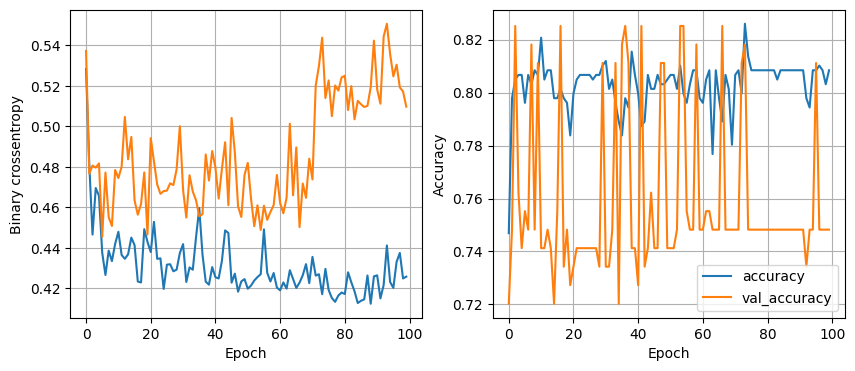

16 nodes, dropout 0, lr 0.1, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.4516 - accuracy: 0.8101
16 nodes, dropout 0, lr 0.1, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.4258 - accuracy: 0.8101
16 nodes, dropout 0, lr 0.005, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.4149 - accuracy: 0.8101
16 nodes, dropout 0, lr 0.005, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.3983 - accuracy: 0.8212


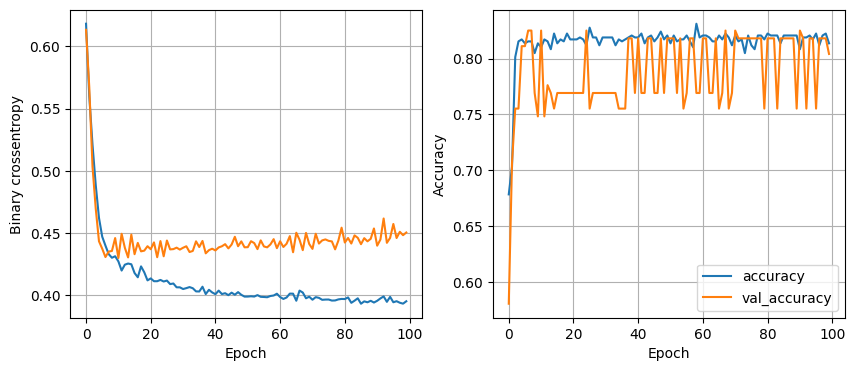

16 nodes, dropout 0, lr 0.005, batch size 128
6/6 [==============================] - 0s 4ms/step - loss: 0.3992 - accuracy: 0.8156
16 nodes, dropout 0, lr 0.001, batch size 32
6/6 [==============================] - 0s 18ms/step - loss: 0.3860 - accuracy: 0.8156


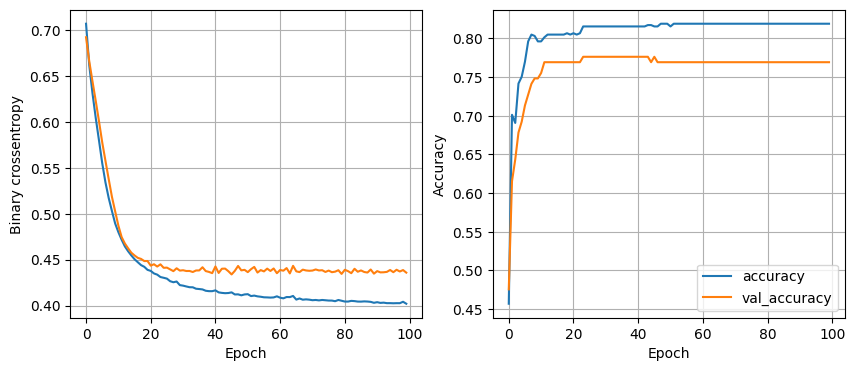

16 nodes, dropout 0, lr 0.001, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.3868 - accuracy: 0.8212
16 nodes, dropout 0, lr 0.001, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.3785 - accuracy: 0.8212


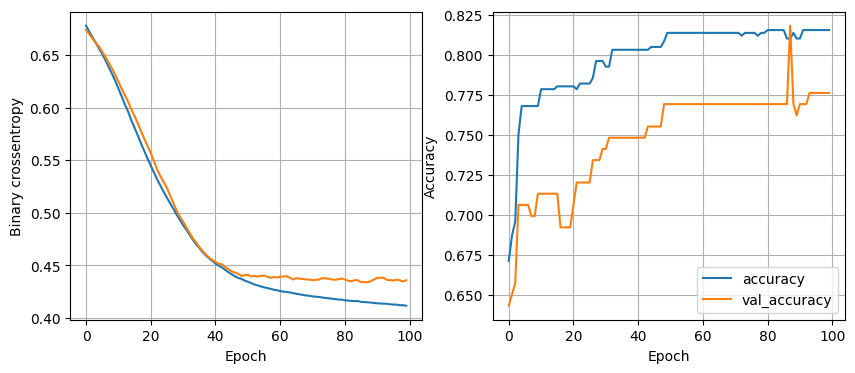

16 nodes, dropout 0.2, lr 0.1, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.4506 - accuracy: 0.8212
16 nodes, dropout 0.2, lr 0.1, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.4112 - accuracy: 0.8045
16 nodes, dropout 0.2, lr 0.1, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.4171 - accuracy: 0.8156
16 nodes, dropout 0.2, lr 0.005, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3951 - accuracy: 0.8156
16 nodes, dropout 0.2, lr 0.005, batch size 64
6/6 [==============================] - 0s 5ms/step - loss: 0.3906 - accuracy: 0.8156
16 nodes, dropout 0.2, lr 0.005, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.3863 - accuracy: 0.8156
16 nodes, dropout 0.2, lr 0.001, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3896 - accuracy: 0.8156
16 nodes, dropout 0.2, lr 0.001, batch size 64
6/6 [============================

In [ ]:
least_val_loss = float('inf')
accuracy = 0
least_loss_model = None
highest_accuracy = None
epochs = 100
for num_nodes in [16, 32]:
    for dropout_prob in[0, 0.2]:
        for lr in [0.1, 0.005, 0.001]:
            for batch_size in [32, 64, 128]:
                print(f"{num_nodes} nodes, dropout {dropout_prob}, lr {lr}, batch size {batch_size}")
                model, history = train_model_relu(X_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs)
                val_loss = model.evaluate(X_test, y_test)


                if val_loss[0] < least_val_loss:
                    least_val_loss = val_loss[0]
                    least_loss_model = model
                    plot_history(history)


                if val_loss[1] > accuracy:
                    highest_accuracy = model
                    accuracy = val_loss[1]


<p>Proviamo a cambiare anche il numero di layer nascosti (2 --> 4), e la funzione di attivazione</p>

In [ ]:
epochs = 100
for num_nodes in [16, 32]:
    for dropout_prob in[0, 0.2]:
        for lr in [0.1, 0.005, 0.001]:
            for batch_size in [32, 64, 128]:
                print(f"{num_nodes} nodes, dropout {dropout_prob}, lr {lr}, batch size {batch_size}")
                model, history = train_model_sig(X_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs)
                val_loss = model.evaluate(X_test, y_test)


                if val_loss[0] < least_val_loss:
                    least_val_loss = val_loss[0]
                    least_loss_model = model


                if val_loss[1] > accuracy:
                    highest_acc_model = model
                    accuracy = val_loss[1]

                    if val_loss[1] == accuracy and val_loss[0] < least_val_loss:
                        least_val_loss = val_loss[0]
                        highest_acc_model = model
                        accuracy = val_loss[1]

16 nodes, dropout 0, lr 0.1, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.4962 - accuracy: 0.7989
16 nodes, dropout 0, lr 0.1, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.6668 - accuracy: 0.6145
16 nodes, dropout 0, lr 0.1, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.3984 - accuracy: 0.8212
16 nodes, dropout 0, lr 0.005, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3915 - accuracy: 0.8212
16 nodes, dropout 0, lr 0.005, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.3898 - accuracy: 0.8212
16 nodes, dropout 0, lr 0.005, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.4028 - accuracy: 0.8212
16 nodes, dropout 0, lr 0.001, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3934 - accuracy: 0.8156
16 nodes, dropout 0, lr 0.001, batch size 64
6/6 [==============================] - 0s 3ms/ste

In [ ]:
print(columns)

['Sex', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Age_categories_Missing', 'Age_categories_Infant', 'Age_categories_Child', 'Age_categories_Teenager', 'Age_categories_Young Adult', 'Age_categories_Adult', 'Age_categories_Senior']


In [ ]:
columns = ['Sex' ,'Pclass_1', 'Pclass_2', 'Pclass_3',
       'Age_categories_Missing','Age_categories_Infant',
       'Age_categories_Child', 'Age_categories_Teenager',
       'Age_categories_Young Adult', 'Age_categories_Adult',
       'Age_categories_Senior']

In [ ]:
predictions = np.round(least_loss_model.predict(test[columns])).astype(int).reshape(-1)


14/14 [==============================] - 0s 2ms/step


In [ ]:
print(predictions)

[0 0 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 0 0 1 0 0 0 0
 1 0 0 0 0 0 1 1 0 0 0 1 0 0 0 1 1 0 0 0 0 0 1 0 0 0 1 0 1 1 0 0 1 1 0 1 0
 1 0 0 1 0 1 0 0 0 0 0 0 1 1 0 1 1 0 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0
 0 1 1 1 0 0 1 0 1 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 1 1 0 1 0 0 1 0 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 1 0 0 1 0 1
 0 1 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 1 0 0 0 0 1 0 1 0
 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 1
 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0
 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0
 1 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 1 1 0
 0 1 0 0 1 1 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 1 0 1 0 0 1 0 1 0 0 0 0
 0 0 1 0 1 1 0 1 0 0 0]


In [ ]:
holdout_ids = test["PassengerId"]
submission_df = {"PassengerId": holdout_ids, "Survived": predictions}
submission = pd.DataFrame(submission_df)
submission.to_csv('titanic_submission_1.csv', index=False)

In [ ]:
print(submission)

     PassengerId  Survived
0            892         0
1            893         0
2            894         0
3            895         0
4            896         1
..           ...       ...
413         1305         0
414         1306         1
415         1307         0
416         1308         0
417         1309         0

[418 rows x 2 columns]


In [ ]:
predictions_1 = np.round(knn_model.predict(test[columns])).astype(int).reshape(-1)
print(predictions)

[0 0 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 0 0 1 0 0 0 0
 1 0 0 0 0 0 1 1 0 0 0 1 0 0 0 1 1 0 0 0 0 0 1 0 0 0 1 0 1 1 0 0 1 1 0 1 0
 1 0 0 1 0 1 0 0 0 0 0 0 1 1 0 1 1 0 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0
 0 1 1 1 0 0 1 0 1 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 1 1 0 1 0 0 1 0 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 1 0 0 1 0 1
 0 1 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 1 0 0 0 0 1 0 1 0
 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 1
 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0
 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0
 1 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 1 1 0
 0 1 0 0 1 1 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 1 0 1 0 0 1 0 1 0 0 0 0
 0 0 1 0 1 1 0 1 0 0 0]


In [ ]:
holdout_ids = test["PassengerId"]
submission_df = {"PassengerId": holdout_ids, "Survived": predictions}
submission = pd.DataFrame(submission_df)
submission.to_csv('titanic_submission_knn.csv', index=False)

In [ ]:
def train_model(x_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs, act_fun):
    nn_model = tf.keras.Sequential([
        tf.keras.layers.Dense(num_nodes, activation=act_fun, input_shape=(11,)),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(num_nodes, activation=act_fun),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(num_nodes, activation=act_fun),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(num_nodes, activation=act_fun),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(num_nodes, activation=act_fun),
        tf.keras.layers.Dropout(dropout_prob),
        tf.keras.layers.Dense(1, activation="sigmoid")
        #usiamo la sigmoide per avere un risultato tra 0 e 1
    ])

    nn_model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])
    history = nn_model.fit(
    x_train, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.2, verbose=0
    )

    return nn_model, history

<h2>Facciamo variare ora anche le funzioni di attivazione con i parametri più efficaci individuati in precedenza</h2>

function gelu, 16 nodes, dropout 0, lr 0.1, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.4127 - accuracy: 0.8212
function gelu, 16 nodes, dropout 0, lr 0.1, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.4417 - accuracy: 0.8156
function gelu, 16 nodes, dropout 0, lr 0.1, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.4064 - accuracy: 0.8212
function gelu, 16 nodes, dropout 0, lr 0.005, batch size 32
6/6 [==============================] - 0s 9ms/step - loss: 0.4038 - accuracy: 0.8212
function gelu, 16 nodes, dropout 0, lr 0.005, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.4030 - accuracy: 0.8156
function gelu, 16 nodes, dropout 0, lr 0.005, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.3866 - accuracy: 0.8268
function gelu, 16 nodes, dropout 0, lr 0.001, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3852 - accura

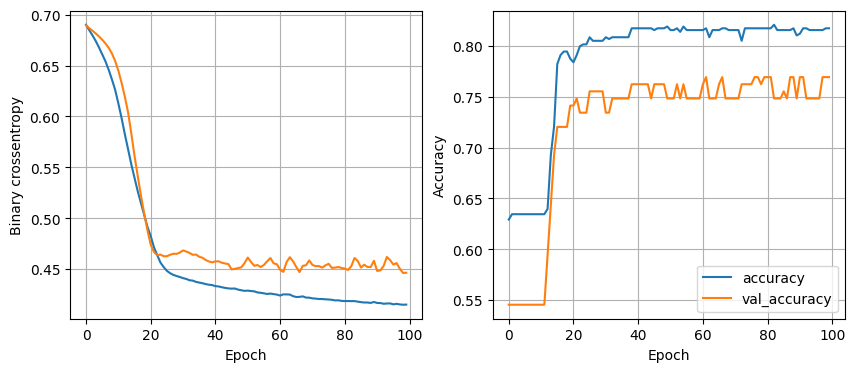

function gelu, 16 nodes, dropout 0.2, lr 0.1, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.6668 - accuracy: 0.6145
function gelu, 16 nodes, dropout 0.2, lr 0.1, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.5325 - accuracy: 0.7430
function gelu, 16 nodes, dropout 0.2, lr 0.1, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.4519 - accuracy: 0.7765
function gelu, 16 nodes, dropout 0.2, lr 0.005, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3864 - accuracy: 0.8156
function gelu, 16 nodes, dropout 0.2, lr 0.005, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.3915 - accuracy: 0.8212
function gelu, 16 nodes, dropout 0.2, lr 0.005, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.3922 - accuracy: 0.8212
function gelu, 16 nodes, dropout 0.2, lr 0.001, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0

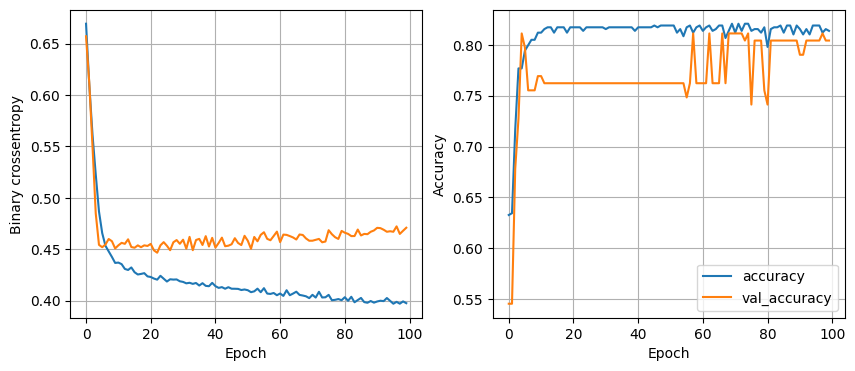

function gelu, 32 nodes, dropout 0, lr 0.001, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.3815 - accuracy: 0.8156
function gelu, 32 nodes, dropout 0, lr 0.001, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.3881 - accuracy: 0.8212
function gelu, 32 nodes, dropout 0.2, lr 0.1, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.6667 - accuracy: 0.6145
function gelu, 32 nodes, dropout 0.2, lr 0.1, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.6683 - accuracy: 0.6145
function gelu, 32 nodes, dropout 0.2, lr 0.1, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.6668 - accuracy: 0.6145
function gelu, 32 nodes, dropout 0.2, lr 0.005, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3977 - accuracy: 0.8212
function gelu, 32 nodes, dropout 0.2, lr 0.005, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.398

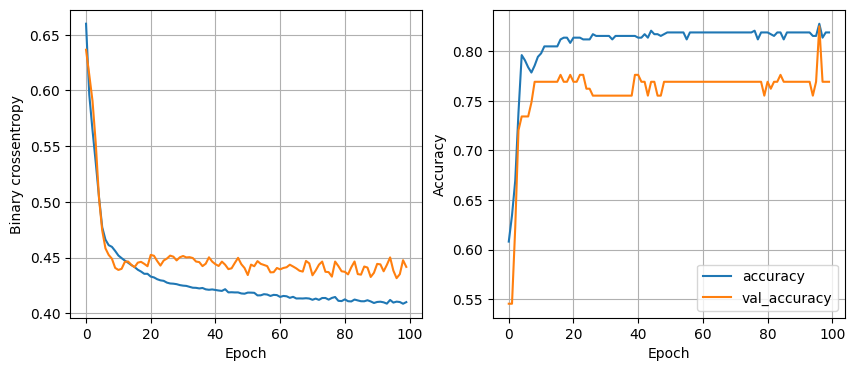

function elu, 32 nodes, dropout 0.2, lr 0.1, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.7721 - accuracy: 0.6145
function elu, 32 nodes, dropout 0.2, lr 0.1, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.6734 - accuracy: 0.6145
function elu, 32 nodes, dropout 0.2, lr 0.1, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.6905 - accuracy: 0.6145
function elu, 32 nodes, dropout 0.2, lr 0.005, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3964 - accuracy: 0.8212
function elu, 32 nodes, dropout 0.2, lr 0.005, batch size 64
6/6 [==============================] - 0s 4ms/step - loss: 0.3938 - accuracy: 0.8212
function elu, 32 nodes, dropout 0.2, lr 0.005, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.3806 - accuracy: 0.8156
function elu, 32 nodes, dropout 0.2, lr 0.001, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3845 -

In [ ]:
epochs = 100
for func in ["gelu", "elu", "hard_sigmoid", "mish", "tanh"]:
    for num_nodes in [16, 32]:
        for dropout_prob in[0, 0.2]:
            for lr in [0.1, 0.005, 0.001]:
                for batch_size in [32, 64, 128]:
                    print(f"function {func}, {num_nodes} nodes, dropout {dropout_prob}, lr {lr}, batch size {batch_size}")
                    model, history = train_model(X_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs, func)
                    val_loss = model.evaluate(X_test, y_test)


                    if val_loss[0] < least_val_loss:
                        least_val_loss = val_loss[0]
                        least_loss_model = model
                        plot_history(history)


                    if val_loss[1] > accuracy:
                        highest_acc_model = model
                        accuracy = val_loss[1]

                        if val_loss[1] == accuracy and val_loss[0] < least_val_loss:
                            least_val_loss = val_loss[0]
                            highest_acc_model = model
                            accuracy = val_loss[1]

<p>Creiamo il file per poter consegnare il nostro risultato</p>

In [ ]:
predictions = np.round(least_loss_model.predict(test[columns])).astype(int).reshape(-1)
print(predictions)

14/14 [==============================] - 0s 2ms/step
[0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 1 0 0 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 1 1 0 0 0 1 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 1 0 0 0 0
 1 0 0 1 0 0 0 0 0 0 0 0 0 1 0 1 0 0 1 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 0 0 0
 0 1 0 1 0 0 1 0 1 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 1 1 0 1 1 0 0 1 0 1
 0 1 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 1 0
 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 1
 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0
 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 0 0 1 1 0 1 0 0 0 1 0
 0 1 0 0 1 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 1 0 0 1 0 1 0 0 0 0
 0 0 1 0 1 0 0 1 0 0 0]


In [ ]:
holdout_ids = test["PassengerId"]
submission_df = {"PassengerId": holdout_ids, "Survived": predictions}
submission = pd.DataFrame(submission_df)
submission.to_csv('titanic_submission_highest.csv', index=False)

In [ ]:
epochs = 100
for func in ["gelu", "exponential", "linear", "selu"]:
    for num_nodes in [16, 32]:
        for dropout_prob in[0, 0.2]:
            for lr in [0.1, 0.005, 0.001]:
                for batch_size in [32, 64, 128]:
                    print(f"function {func}, {num_nodes} nodes, dropout {dropout_prob}, lr {lr}, batch size {batch_size}")
                    model, history = train_model(X_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs, func)
                    val_loss = model.evaluate(X_test, y_test)


                    if val_loss[0] < least_val_loss:
                        least_val_loss = val_loss[0]
                        least_loss_model = model
                        plot_history(history)


                    if val_loss[1] > accuracy:
                        highest_acc_model = model
                        accuracy = val_loss[1]

                        if val_loss[1] == accuracy and val_loss[0] < least_val_loss:
                            least_val_loss = val_loss[0]
                            highest_acc_model = model
                            accuracy = val_loss[1]

function gelu, 16 nodes, dropout 0, lr 0.1, batch size 32
6/6 [==============================] - 0s 5ms/step - loss: 0.6679 - accuracy: 0.6145
function gelu, 16 nodes, dropout 0, lr 0.1, batch size 64
6/6 [==============================] - 0s 5ms/step - loss: 0.6652 - accuracy: 0.6145
function gelu, 16 nodes, dropout 0, lr 0.1, batch size 128
6/6 [==============================] - 0s 4ms/step - loss: 0.4310 - accuracy: 0.8156
function gelu, 16 nodes, dropout 0, lr 0.005, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.4036 - accuracy: 0.8156
function gelu, 16 nodes, dropout 0, lr 0.005, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.3956 - accuracy: 0.8212
function gelu, 16 nodes, dropout 0, lr 0.005, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.4002 - accuracy: 0.8156
function gelu, 16 nodes, dropout 0, lr 0.001, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3882 - accura

In [ ]:
predictions = np.round(least_loss_model.predict(test[columns])).astype(int).reshape(-1)
print(predictions)

14/14 [==============================] - 0s 2ms/step
[0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 1 0 0 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 1 1 0 0 0 1 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 1 0 0 0 0
 1 0 0 1 0 0 0 0 0 0 0 0 0 1 0 1 0 0 1 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 0 0 0
 0 1 0 1 0 0 1 0 1 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 1 1 0 1 1 0 0 1 0 1
 0 1 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 1 0
 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 1
 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0
 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 0 0 1 1 0 1 0 0 0 1 0
 0 1 0 0 1 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 1 0 0 1 0 1 0 0 0 0
 0 0 1 0 1 0 0 1 0 0 0]


In [ ]:
holdout_ids = test["PassengerId"]
submission_df = {"PassengerId": holdout_ids, "Survived": predictions}
submission = pd.DataFrame(submission_df)
submission.to_csv('titanic_submission.csv', index=False)

In [ ]:
conf_matrix = confusion_matrix(y_test, predictions)
pd.DataFrame(conf_matrix, columns=['Survived', 'Died'], index=[['pred_Survived', 'pred_Died']])

,Survived,Died
pred_Survived,96,14
pred_Died,20,49


function softmax, 16 nodes, dropout 0, lr 0.1, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.6671 - accuracy: 0.6145


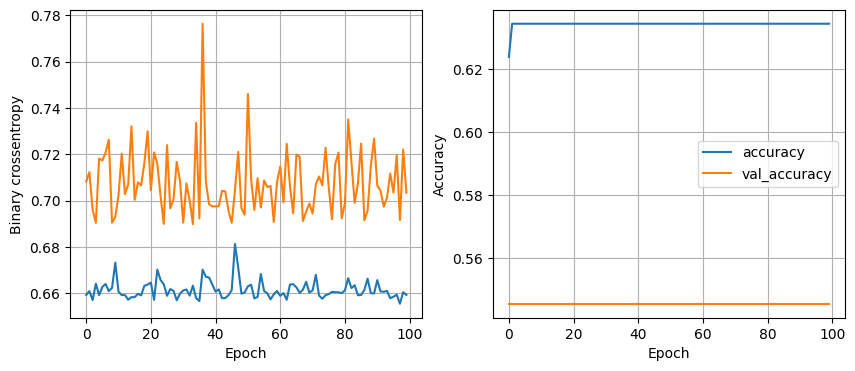

function softmax, 16 nodes, dropout 0, lr 0.1, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.6794 - accuracy: 0.6145
function softmax, 16 nodes, dropout 0, lr 0.1, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.6678 - accuracy: 0.6145
function softmax, 16 nodes, dropout 0, lr 0.005, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3881 - accuracy: 0.8156


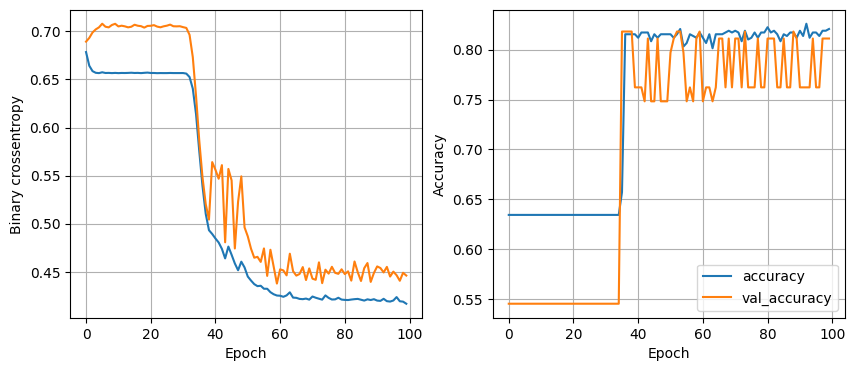

function softmax, 16 nodes, dropout 0, lr 0.005, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.3909 - accuracy: 0.8156
function softmax, 16 nodes, dropout 0, lr 0.005, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.4633 - accuracy: 0.8212
function softmax, 16 nodes, dropout 0, lr 0.001, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.6263 - accuracy: 0.6145
function softmax, 16 nodes, dropout 0, lr 0.001, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.6675 - accuracy: 0.6145
function softmax, 16 nodes, dropout 0, lr 0.001, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.6673 - accuracy: 0.6145
function softmax, 16 nodes, dropout 0.2, lr 0.1, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.4593 - accuracy: 0.8156
function softmax, 16 nodes, dropout 0.2, lr 0.1, batch size 64
6/6 [==============================] - 0s 3ms/s

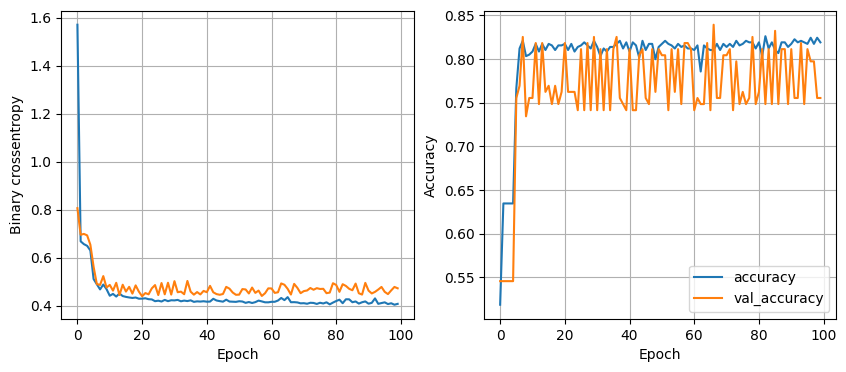

function softplus, 16 nodes, dropout 0, lr 0.005, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3811 - accuracy: 0.8156


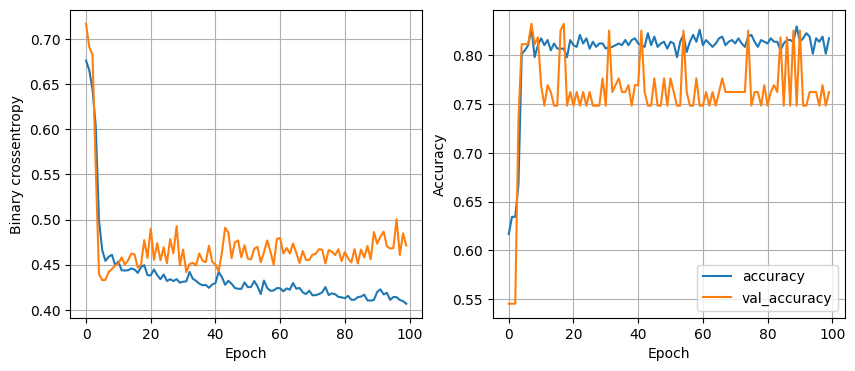

function softplus, 16 nodes, dropout 0, lr 0.005, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.3914 - accuracy: 0.8212
function softplus, 16 nodes, dropout 0, lr 0.005, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.3845 - accuracy: 0.8212
function softplus, 16 nodes, dropout 0, lr 0.001, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3917 - accuracy: 0.8156
function softplus, 16 nodes, dropout 0, lr 0.001, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.3906 - accuracy: 0.8212
function softplus, 16 nodes, dropout 0, lr 0.001, batch size 128
6/6 [==============================] - 0s 4ms/step - loss: 0.3972 - accuracy: 0.8212
function softplus, 16 nodes, dropout 0.2, lr 0.1, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.4687 - accuracy: 0.8268
function softplus, 16 nodes, dropout 0.2, lr 0.1, batch size 64
6/6 [==============================] - 0

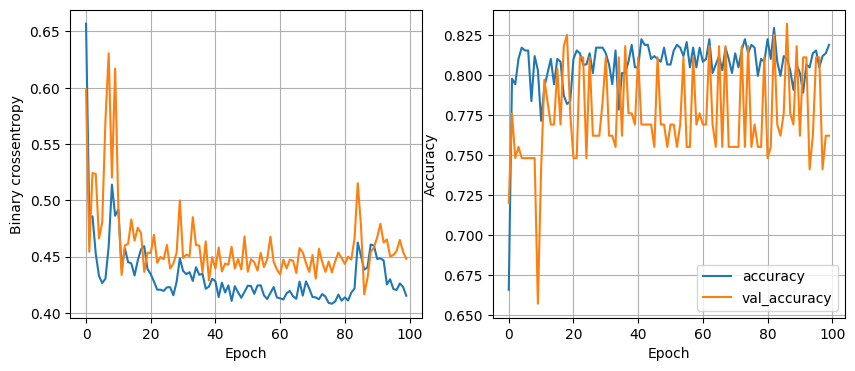

function softsign, 16 nodes, dropout 0, lr 0.1, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.3893 - accuracy: 0.8324
function softsign, 16 nodes, dropout 0, lr 0.005, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3979 - accuracy: 0.8156
function softsign, 16 nodes, dropout 0, lr 0.005, batch size 64
6/6 [==============================] - 0s 4ms/step - loss: 0.4031 - accuracy: 0.8156
function softsign, 16 nodes, dropout 0, lr 0.005, batch size 128
6/6 [==============================] - 0s 4ms/step - loss: 0.4064 - accuracy: 0.8212
function softsign, 16 nodes, dropout 0, lr 0.001, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3866 - accuracy: 0.8156
function softsign, 16 nodes, dropout 0, lr 0.001, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.3824 - accuracy: 0.8156
function softsign, 16 nodes, dropout 0, lr 0.001, batch size 128
6/6 [==============================] - 0s

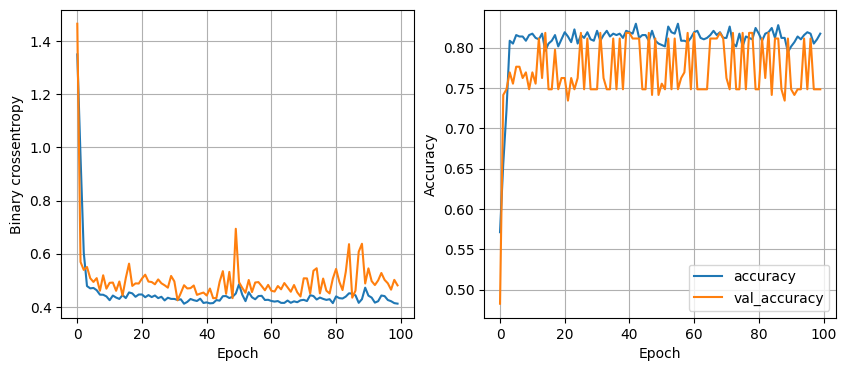

function selu, 16 nodes, dropout 0, lr 0.005, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.3858 - accuracy: 0.8212
function selu, 16 nodes, dropout 0, lr 0.005, batch size 64
6/6 [==============================] - 0s 3ms/step - loss: 0.4130 - accuracy: 0.8212
function selu, 16 nodes, dropout 0, lr 0.005, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.4028 - accuracy: 0.8156
function selu, 16 nodes, dropout 0, lr 0.001, batch size 32
6/6 [==============================] - 0s 4ms/step - loss: 0.4033 - accuracy: 0.8212
function selu, 16 nodes, dropout 0, lr 0.001, batch size 64
6/6 [==============================] - 0s 5ms/step - loss: 0.4013 - accuracy: 0.8101
function selu, 16 nodes, dropout 0, lr 0.001, batch size 128
6/6 [==============================] - 0s 3ms/step - loss: 0.3887 - accuracy: 0.8156
function selu, 16 nodes, dropout 0.2, lr 0.1, batch size 32
6/6 [==============================] - 0s 3ms/step - loss: 0.6772 - 

In [ ]:
least_val_loss = float('inf')
accuracy = 0
epochs = 100
for func in ["softmax", "softplus", "softsign", "selu"]:
    for num_nodes in [16, 32]:
        for dropout_prob in[0, 0.2]:
            for lr in [0.1, 0.005, 0.001]:
                for batch_size in [32, 64, 128]:
                    print(f"function {func}, {num_nodes} nodes, dropout {dropout_prob}, lr {lr}, batch size {batch_size}")
                    model, history = train_model(X_train, y_train, num_nodes, dropout_prob, lr, batch_size, epochs, func)
                    val_loss = model.evaluate(X_test, y_test)


                    if val_loss[0] < least_val_loss:
                        least_val_loss = val_loss[0]
                        least_loss_model = model
                        plot_history(history)


                    if val_loss[1] > accuracy:
                        highest_acc_model = model
                        accuracy = val_loss[1]

                        if val_loss[1] == accuracy and val_loss[0] < least_val_loss:
                            least_val_loss = val_loss[0]
                            highest_acc_model = model
                            accuracy = val_loss[1]

In [ ]:
predictions = np.round(highest_acc_model.predict(test[columns])).astype(int).reshape(-1)
print(predictions)

14/14 [==============================] - 0s 2ms/step
[0 0 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 0 0 1 1 0 0 1
 1 0 0 0 0 0 1 1 0 0 0 1 0 0 0 1 1 0 0 0 0 0 1 0 0 0 1 0 1 1 0 0 1 1 0 1 0
 1 0 0 1 0 1 0 0 0 0 0 0 1 1 1 1 1 0 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0
 1 1 1 1 0 0 1 0 1 1 0 1 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 1 1 0 1 1 0 1 0 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 1 0 0 1 0 1
 0 1 0 1 0 0 0 0 0 0 0 0 1 0 1 1 1 0 1 0 0 1 0 1 0 0 0 0 1 0 0 1 0 1 0 1 0
 1 0 1 1 0 1 0 0 0 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 1 1 1 0 0 0 0 0 0 0 1
 0 0 0 1 1 0 0 0 0 1 0 0 0 1 1 0 1 0 0 0 0 1 1 1 0 1 0 0 0 0 0 0 1 0 0 0 0
 1 0 0 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0
 1 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 0 1 1 0 1 1 0
 0 1 0 0 1 1 1 0 0 1 0 0 1 1 0 1 0 0 0 0 0 1 0 0 0 1 0 1 0 0 1 0 1 0 0 0 0
 0 1 1 1 1 1 0 1 0 0 0]


In [ ]:
holdout_ids = test["PassengerId"]
submission_df = {"PassengerId": holdout_ids, "Survived": predictions}
submission = pd.DataFrame(submission_df)
submission.to_csv('titanic_submission_champ.csv', index=False)